In [1]:
from preprocessing import load_splits, build_preprocessor, rmse, FEATURES, TARGET
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


In [3]:
train_split, val_split = load_splits()

preprocessor = build_preprocessor()
X_train = preprocessor.fit_transform(train_split[FEATURES])
X_val = preprocessor.transform(val_split[FEATURES])

y_train = train_split[TARGET]
y_val = val_split[TARGET]

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

print("Train RMSE:", rmse(y_train, train_pred))
print("Validation RMSE:", rmse(y_val, val_pred))

Train RMSE: 515.1375702377961
Validation RMSE: 550.0382720872328


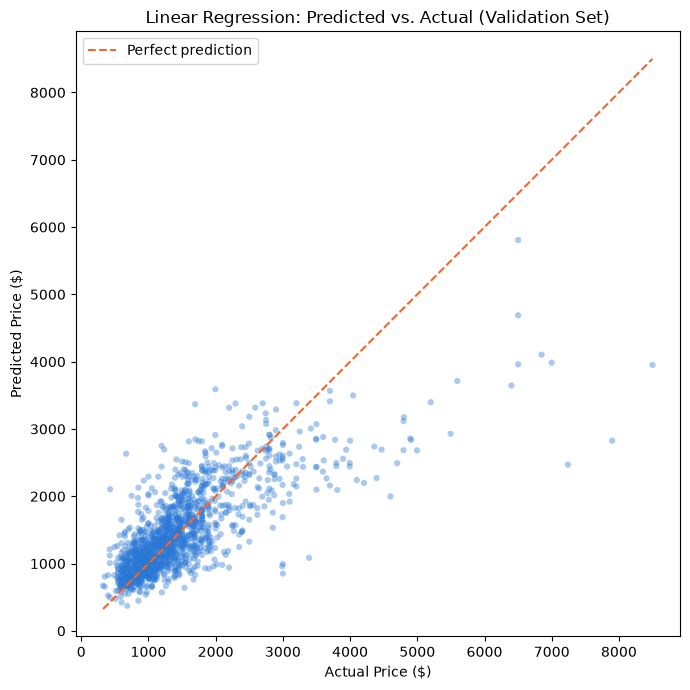

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(y_val, val_pred, alpha=0.4, s=20, color='#2a78d6', edgecolors='none')

lims = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
ax.plot(lims, lims, color='#eb6834', linestyle='--', linewidth=1.5, label='Perfect prediction')

ax.set_xlabel('Actual Price ($)')
ax.set_ylabel('Predicted Price ($)')
ax.set_title('Linear Regression: Predicted vs. Actual (Validation Set)')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()